# Basics of Mobile Robotics - Project

## Table of Contents

- [Introduction](#introduction)
    - [Group](#group) 
- [Camera and Thymio Connection](#camera-and-thymio-connexion)
- [Vision Processing](#vision-processing)
- [Filtering](#filtering)
- [Navigation](#navigation)
    - [Global Navigation](#global-navigation)
    - [Local Navigation](#local-navigation)
- [Results](#results)
- [Conclusion](#conclusion)

## Introduction 
This project is part of the course *Basics of Mobile Robotics (MICRO-452)* at EPFL and is initially made by group of four students. The class is given by Professor Francesco Mondada from [MOBOTS lab](https://www.epfl.ch/labs/mobots/).

### Goal of the project 
This project aim to implement diverse algorithme seen in course. 
- Autonomous navigation through a specific goal following the optimal path. 
- Unexpected object avoidance. 
- Keep track of the goal if blind through a extended Kalman filter. 
- Be able to reach any position in the predefined map.

### Group
Our team consists of three first-year Master's students in Robotics at EPFL. The work load has been equally separated between members. The final assembly of the code has been done by everyone. 
| Name            | SCIPER | Role                       |
|-----------------|--------|----------------------------|
| Linus  Crugnola | 340864 | Filtering                  |
| Alexis Bollack  | 406474 | Local & Global navigation  |
| Maxime Luyet    | 345770 | Vision                     |



In [1]:
%reload_ext autoreload
%autoreload 2

import sys
import time
import cv2
import numpy as np
import tdmclient.notebook as tdm
sys.path.append('./src')

#from filtering import *
from src.vision import Vision 
from src.global_navigation import GlobalNavigation
from src.local_navigation import LocalNavigation
from src.filtering import ExtendedKalmanFilter
from src.control import Control
#from utils import utils

In [2]:
cam_id= 8
kalman = ExtendedKalmanFilter()
vision = Vision(cam_id=cam_id)
global_nav = GlobalNavigation()
local_nav = LocalNavigation()
control = Control()

In [3]:
vision = Vision(cam_id=cam_id)
vision.message_from_vision()

#Declare your other instance here 

Vision module is correctly linked.


In [4]:
vision.disconnect_webcam()

## Camera and Thymio connexion 

Here we setup the connexion to the other perhiphericals. 

### Camera connection 

In [4]:
#ERREUR, la condition vision.webcam_connection() 
#est exécutée 2 fois pour une raison inconnue 
try:
    print("Connexion to camera ...")
    if not vision.webcam_connection():
        print("Failed to connect to camera")
        exit(1)
    else:
        print("Webcam connected")

    # start_time = time.time()
    # while time.time() - start_time < 3:
    #     original_frame = vision._get_original_frame()
    #     utils.display_frames(original_frame, None, None)
except KeyboardInterrupt: 
    print("Program interrupted by user.")
    pass
finally: 
    vision.disconnect_webcam()

Connexion to camera ...
Webcam connected successfully!
Webcam connected
Webcam disconnected


In [5]:
vision.webcam_connection()

Webcam connected successfully!


True

### Test Camera

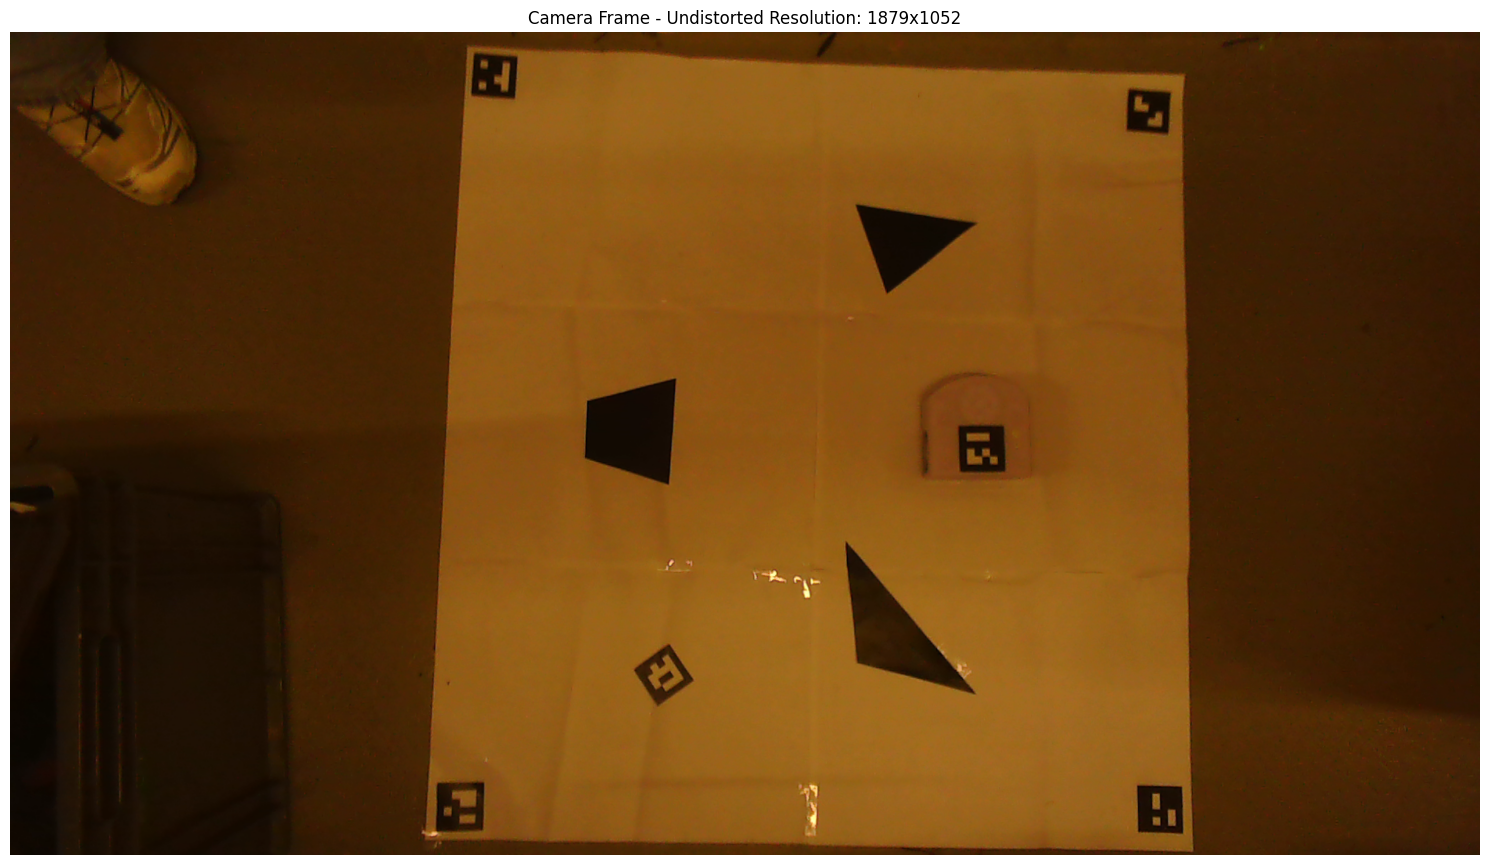

Frame shape (Height x Width x Channels): (1052, 1879, 3)
Frame captured successfully!


In [6]:
#RETESEER LES VALEURS DE LA CAMERA 

#=============================================
#Test of camera capture and undistortion
#=============================================

import matplotlib.pyplot as plt

# Capture frame from camera (undistorted frame)
frame = vision._get_frame()

if frame is not None:
    # Convert BGR (OpenCV) to RGB (matplotlib)
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    
    # Display the image
    plt.figure(figsize=(15, 10))
    plt.imshow(frame_rgb)
    plt.title(f"Camera Frame - Undistorted Resolution: {frame.shape[1]}x{frame.shape[0]}")
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    
    print(f"Frame shape (Height x Width x Channels): {frame.shape}")
    print(f"Frame captured successfully!")
else:
    print("Failed to capture frame")

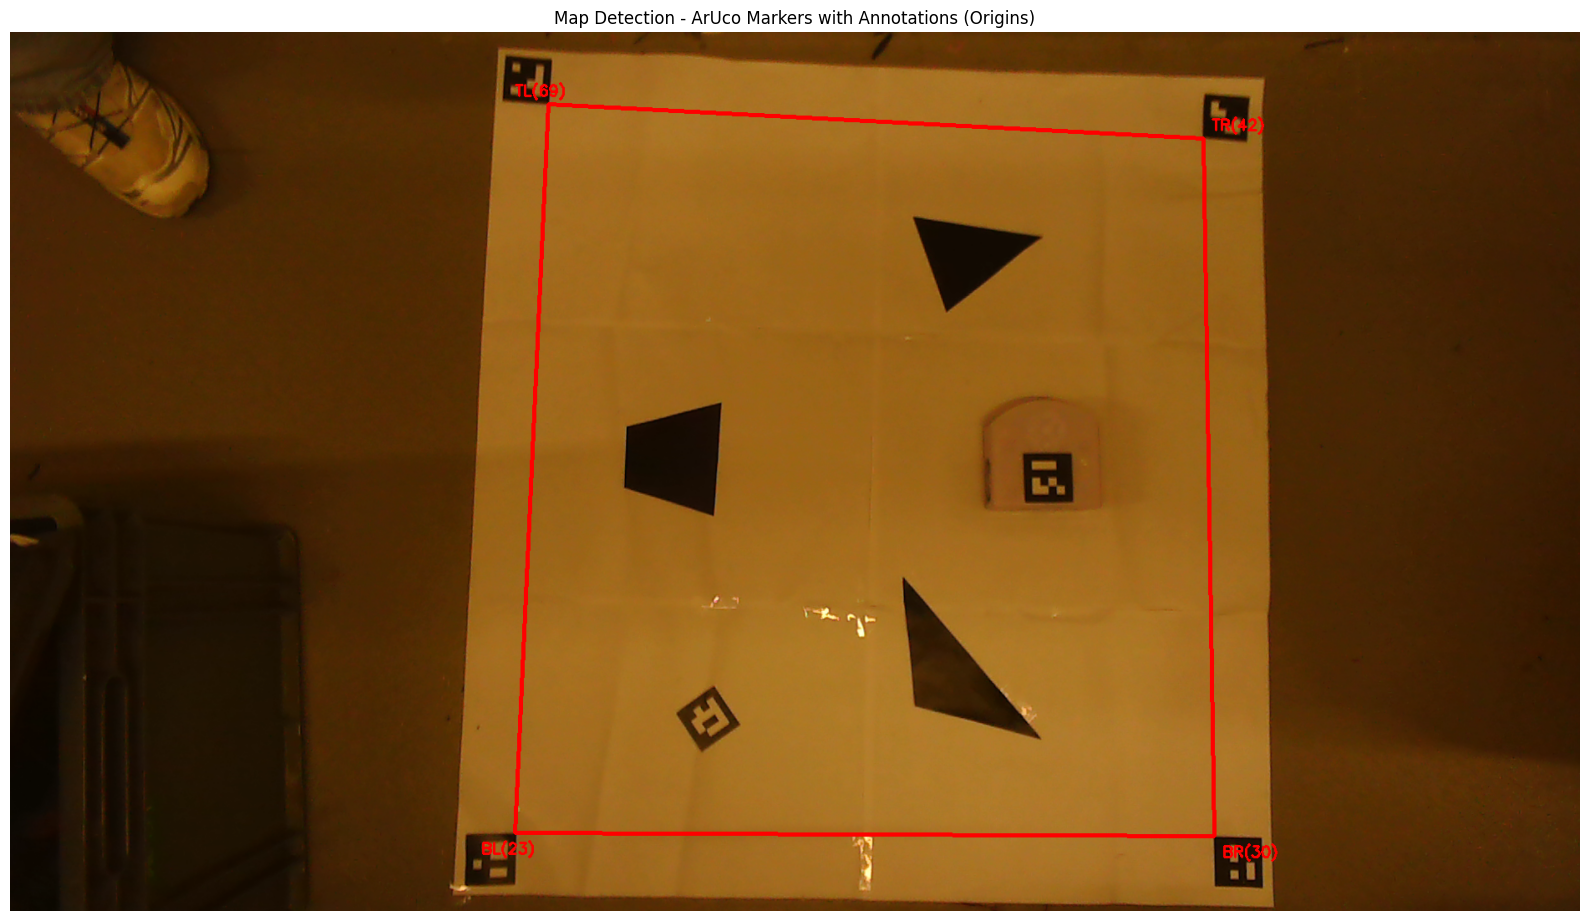

Detected ArUco marker origin positions (Top-Left corner):
  TL (69): (644.0, 86.0)
  TR (42): (1428.0, 127.0)
  BL (23): (604.0, 958.0)
  BR (30): (1441.0, 962.0)


In [7]:
#============================================
#Test of map detection with aruco markers
#============================================

import cv2
import matplotlib.pyplot as plt
import numpy as np
from src import utils

# Capture frame
before_map_crop = vision._get_frame()

if before_map_crop is not None:
    # Create a copy for drawing (before detection modifies the frame)
    frame_with_markers = before_map_crop.copy()
    
    # Detect ArUco markers (this will draw on the copy)
    img, corner_pos = vision._detect_map_markers(frame_with_markers)
    
    if corner_pos is not None:
        # Extract the 4 corner markers from dictionary in correct order [TL, TR, BL, BR]
        corners_array = np.array([
            corner_pos[69],  # TL
            corner_pos[42],  # TR
            corner_pos[23],  # BL
            corner_pos[30]   # BR
        ])
        
        # Draw red borders connecting the 4 corner markers using utils
        img = utils.draw_red_line_in_image(corners_array, img)
        
        # Convert BGR to RGB for matplotlib
        frame_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Display the result
        plt.figure(figsize=(16, 10))
        plt.imshow(frame_rgb)
        plt.title("Map Detection - ArUco Markers with Annotations (Origins)")
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        
        # Print marker positions (origins = top-left corners)
        print("Detected ArUco marker origin positions (Top-Left corner):")
        for marker_id in [69, 42, 23, 30]:
            if marker_id in corner_pos:
                x, y = corner_pos[marker_id]
                marker_name = {69: "TL", 42: "TR", 23: "BL", 30: "BR"}[marker_id]
                print(f"  {marker_name} ({marker_id}): ({x:.1f}, {y:.1f})")
        
    else:
        print("Failed to detect all ArUco markers!")
        print("Make sure all 6 markers are visible: 69, 42, 23, 30 (corners), 78 (robot), 53 (goal)")
else:
    print("Failed to capture frame")

Capturing frame and computing bird's eye view...


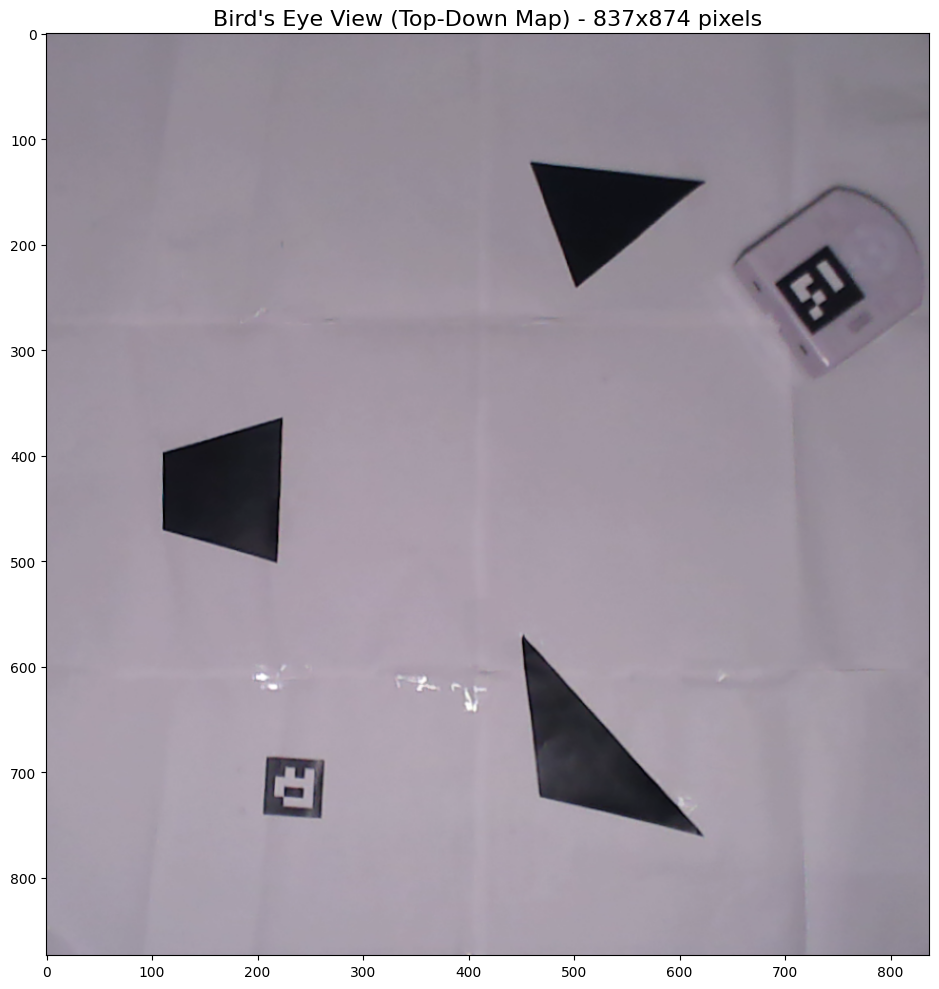


 Bird's eye view extracted successfully!
  Map dimensions: 837 x 874 pixels


In [30]:
#============================================
#Test: Bird's Eye View (Top-Down Map)
#============================================
import matplotlib.pyplot as plt
import numpy as np

print("Capturing frame and computing bird's eye view...")

# Get bird's eye view directly (captures frame internally)
birds_eye_view = vision.get_birds_eye_view()

if birds_eye_view is not None:
    # Convert BGR to RGB for matplotlib display
    map_rgb = cv2.cvtColor(birds_eye_view, cv2.COLOR_BGR2RGB)
    
    # Get map dimensions
    height, width = birds_eye_view.shape[:2]
    
    # Display the bird's eye view map
    plt.figure(figsize=(14, 10))
    plt.imshow(map_rgb)
    plt.title(f"Bird's Eye View (Top-Down Map) - {width}x{height} pixels", fontsize=16)
    # plt.xlabel("X (pixels)", fontsize=12)
    # plt.ylabel("Y (pixels)", fontsize=12)
    # plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    print(f"\n Bird's eye view extracted successfully!")
    print(f"  Map dimensions: {width} x {height} pixels")  
else:
    print("✗ Failed to get bird's eye view.")
    print("  Make sure:")
    print("  - Camera is connected")
    print("  - All 4 corner markers are visible (IDs: 42, 30, 69, 23)")
    print("  - Markers are not obscured or too close to frame edges")


### Test robot pose and occupancy grid

In [6]:
birds_eye_view = vision.get_birds_eye_view()
#robot_pose = vision.get_robot_position(birdseye_view=birds_eye_view)
print("pixels_per_cm:", vision.pixels_per_cm)
occupancy_grid = vision.detect_obstacles(birds_eye_view,pixels_per_cm=vision.pixels_per_cm)
# Print statistics
total_cells = occupancy_grid.size
obstacle_cells = np.sum(occupancy_grid)
free_cells = total_cells - obstacle_cells
obstacle_percentage = (obstacle_cells / total_cells) * 100

print(f"\n✓ Occupancy grid generated successfully!")
print(f"  Grid size: {occupancy_grid.shape[1]} x {occupancy_grid.shape[0]} cells")
print(f"  Total cells: {total_cells}")
print(f"  Obstacle cells: {-obstacle_cells} ({-obstacle_percentage:.1f}%)")
print(f"  Free cells: {free_cells} ({100+obstacle_percentage:.1f}%)")


pixels_per_cm: 11.80281690140845
Dilation kernel size (pixels): 129

✓ Occupancy grid generated successfully!
  Grid size: 838 x 874 cells
  Total cells: 732412
  Obstacle cells: 164584 (22.5%)
  Free cells: 896996 (77.5%)


In [7]:
print("occupancy_grid:", occupancy_grid)
print("min:", np.min(occupancy_grid))
print("max:", np.max(occupancy_grid))

occupancy_grid: [[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
min: -1
max: 0


In [8]:
# Display with opencv
occupancy_grid_display = 255 -(occupancy_grid * (-255.0))
print(occupancy_grid_display)

[[255. 255. 255. ... 255. 255. 255.]
 [255. 255. 255. ... 255. 255. 255.]
 [255. 255. 255. ... 255. 255. 255.]
 ...
 [255. 255. 255. ... 255. 255. 255.]
 [255. 255. 255. ... 255. 255. 255.]
 [255. 255. 255. ... 255. 255. 255.]]


### Test Global path

Detected IDs: [[78]
 [53]]
goal_pose = (687, 242)
robot pose = [257, 722, np.float64(-4.685899945185084)]
smooth_path = [(257, 722), (547, 382), (687, 242)]


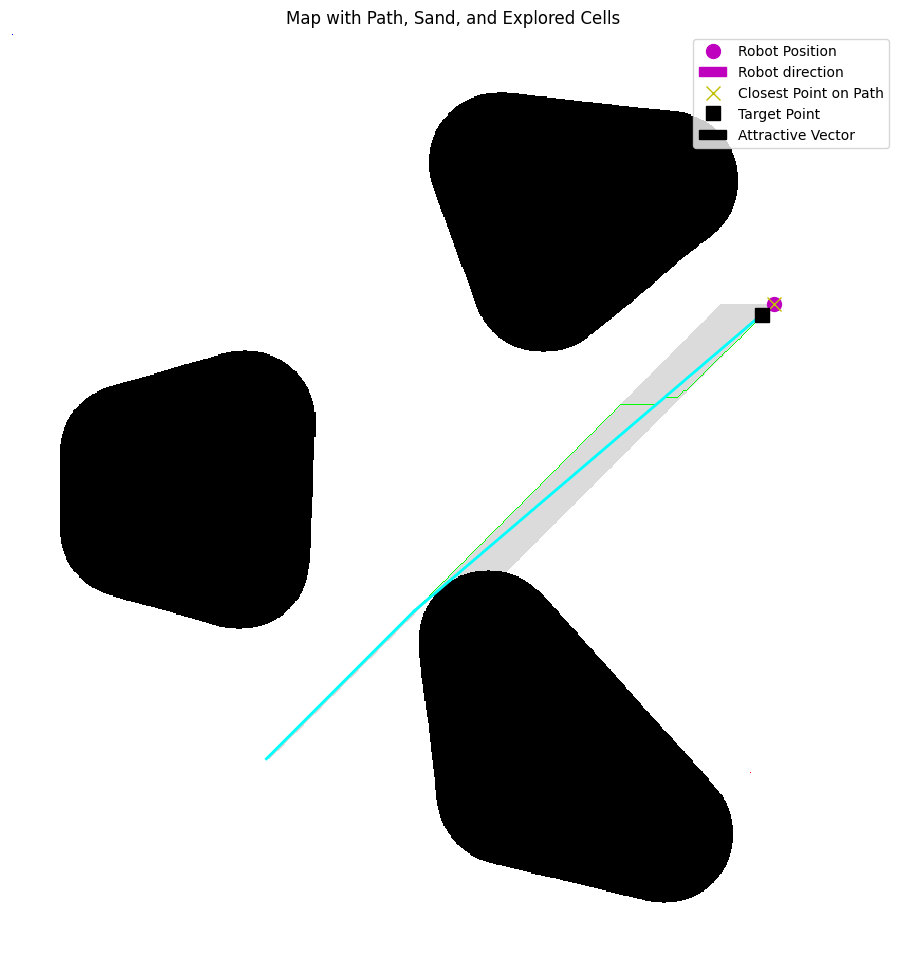

In [13]:
birds_eye_view = vision.get_birds_eye_view()
_, robot_pose = vision.get_robot_position(birdseye_view=birds_eye_view)
_, goal_pose = vision.get_goal_position(birdseye_view=birds_eye_view)
robot_pose = [int(robot_pose[1]), int(robot_pose[0]), robot_pose[2]*180.0/np.pi]
goal_pose = (int(goal_pose[1]), int(goal_pose[0]))
# INVERT X AND Y
print("goal_pose =", goal_pose)
print("robot pose =", robot_pose)
if robot_pose is not None:
    robot_pose_astar = (robot_pose[0], robot_pose[1])
    path8, explored8, op8 = global_nav.grid_search_astar(occupancy_grid, robot_pose_astar, goal_pose)
    smooth_path = global_nav.grid_path_smoothing(path8, occupancy_grid)
    print("smooth_path =", smooth_path)
    closest_point = global_nav.find_closest_point_smoothed_path(robot_pose[:2], smooth_path)
    target_point = global_nav.target_point(closest_point, look_ahead_distance=15.0, path=smooth_path)
    attractive_vector = global_nav.direction_attraction(robot_pose[:2], target_point)
    if path8:
        global_nav.display_map(occupancy_grid, path8, 
                            global_nav.SearchStart, 
                            global_nav.SearchGoal, 
                            explored8, smooth_path, 
                            robot_pose=robot_pose, 
                            closest_point=closest_point, 
                            target_point=target_point,
                            attractive_vector=attractive_vector)
    else:
        print("No path found with A* (8-connected)")
else:
    print("Robot position could not be determined.")

robot pose = [478, 466, np.float64(0.06656816601753235)]
goal_pose = (687, 242)


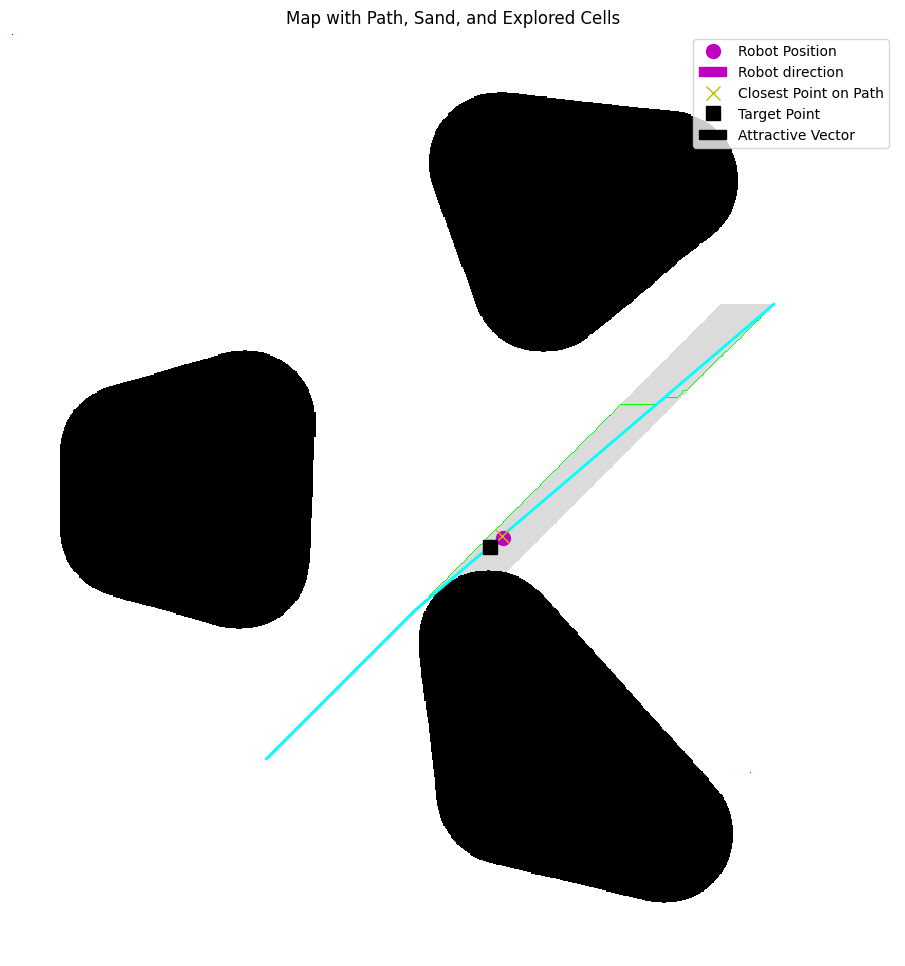

v = 9.080759345199512
omega = -1.5769775982742078
left_wheel_speed = 4
right_wheel_speed = 4


In [49]:
_, robot_pose = vision.get_robot_position(birdseye_view=vision.get_birds_eye_view())
robot_pose = [int(robot_pose[1]), int(robot_pose[0]), robot_pose[2]]
# INVERT X AND Y
print("robot pose =", robot_pose)
print("goal_pose =", goal_pose)
if robot_pose is not None:
    closest_point = global_nav.find_closest_point_smoothed_path(robot_pose[:2], smooth_path)
    target_point = global_nav.target_point(closest_point, look_ahead_distance=15.0, path=smooth_path)
    attractive_vector = global_nav.direction_attraction(robot_pose[:2], target_point)
    target_point = [target_point[0] , target_point[1], 0.0]
    if path8:
        global_nav.display_map(occupancy_grid, path8, 
                            global_nav.SearchStart, 
                            global_nav.SearchGoal, 
                            explored8, smooth_path, 
                            robot_pose=robot_pose, 
                            closest_point=closest_point, 
                            target_point=target_point,
                            attractive_vector=attractive_vector)
    if attractive_vector is not None:
        left_wheel_speed, right_wheel_speed = control.control(robot_pose=robot_pose, goal_pose=target_point)
        print("left_wheel_speed =", left_wheel_speed)
        print("right_wheel_speed =", right_wheel_speed)
    else:
        print("No path found with A* (8-connected)")
else:
    print("Robot position could not be determined.")

### Test Kalman

In [ ]:
# Connect to robot
await tdm.start()
print("Connected to Thymio")

In [22]:
@tdm.sync_var
def robot_set_speed(left_speed, right_speed):
    global motor_left_target, motor_right_target
    motor_left_target = left_speed
    motor_right_target = right_speed

@tdm.sync_var
def robot_stop():
    global motor_left_target, motor_right_target
    motor_left_target = 0
    motor_right_target = 0

@tdm.sync_var
def robot_get_speed():
    global motor_left_speed, motor_right_speed
    return motor_left_speed, motor_right_speed

In [ ]:
# 1- Kalman init state
Y_map_size = 908
robot_pose = vision.get_robot_position(birdseye_view=vision.get_birds_eye_view())
# add theta manually
robot_pose = (int(robot_pose[1]), int(robot_pose[0]), 0)
robot_pose_transformed = (robot_pose[0], Y_map_size - robot_pose[1], -robot_pose[2])
kalman.init_state(robot_pose_transformed)

# 2 - Move robot
Control.set_speed(100,100)
time.sleep(1)
Control.set_speed(0,0)

# 3- Kalman predict and update
left_speed, right_speed = robot_get_speed()
predicted_state = kalman.predict(right_speed_m=right_speed, left_speed_m=left_speed, dt=1.0, verbose=True)

# Capture new pose
birds_eye_view = vision.get_birds_eye_view()
measured_pose = vision.get_robot_position(birdseye_view=birds_eye_view)
measured_pose = (int(measured_pose[1]), int(measured_pose[0]), np.pi/2)
measured_pose_transformed = (measured_pose[0], Y_map_size - measured_pose[1], -measured_pose[2])

updated_state = kalman.update(measured_pose_transformed, verbose=True)
updated_state_transformed = (updated_state[0], Y_map_size - updated_state[1], -updated_state[2])